## Grouping the psv patient files into one parquet file

In [2]:
# import pandas as pd, glob, os

# dfs = []
# for set_name in ["training_setA", "training_setB"]:
#     for f in glob.glob(f"{set_name}/*.psv"):
#         d = pd.read_csv(f, sep="|")
#         d["patient_id"] = os.path.basename(f).replace(".psv", "")
#         d["hospital"] = set_name[-1]
#         dfs.append(d)

# df = pd.concat(dfs, ignore_index=True)
# df.to_parquet("sepsis_all.parquet")

## Data Inspection

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_parquet("sepsis_all.parquet")
df.head(10)

,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,patient_id,hospital
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,1,0,p000001,A
1,97.0,95.0,NaN,98.0,75.33,NaN,19.0,NaN,NaN,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,2,0,p000001,A
2,89.0,99.0,NaN,122.0,86.00,NaN,22.0,NaN,NaN,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,3,0,p000001,A
3,90.0,95.0,NaN,NaN,NaN,NaN,30.0,NaN,24.0,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,4,0,p000001,A
4,103.0,88.5,NaN,122.0,91.33,NaN,24.5,NaN,NaN,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,5,0,p000001,A
5,110.0,91.0,NaN,NaN,NaN,NaN,22.0,NaN,NaN,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,6,0,p000001,A
6,108.0,92.0,36.11,123.0,77.00,NaN,29.0,NaN,NaN,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,7,0,p000001,A
7,106.0,90.5,NaN,93.0,76.33,NaN,29.0,NaN,NaN,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,8,0,p000001,A
8,104.0,95.0,NaN,133.0,88.33,NaN,26.0,NaN,NaN,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,9,0,p000001,A
9,102.0,91.0,NaN,134.0,87.33,NaN,30.0,NaN,NaN,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,10,0,p000001,A


In [5]:
df = df.drop(columns=["Unit1", "Unit2", "hospital"])

In [6]:
df.shape

(1423119, 40)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1423119 entries, 0 to 1423118
Data columns (total 40 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   HR                1285344 non-null  float64
 1   O2Sat             1238708 non-null  float64
 2   Temp              480331 non-null   float64
 3   SBP               1214818 non-null  float64
 4   MAP               1248826 non-null  float64
 5   DBP               954566 non-null   float64
 6   Resp              1212182 non-null  float64
 7   EtCO2             46928 non-null    float64
 8   BaseExcess        83835 non-null    float64
 9   HCO3              64794 non-null    float64
 10  FiO2              126218 non-null   float64
 11  pH                104512 non-null   float64
 12  PaCO2             83222 non-null    float64
 13  SaO2              50922 non-null    float64
 14  AST               22938 non-null    float64
 15  BUN               99440 non-null    float64
 16  Alkalinepho

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
HR,1285344.0,84.623937,17.284029,20.00,72.00,83.50,95.50,280.00
O2Sat,1238708.0,97.203322,2.942987,20.00,96.00,98.00,99.50,100.00
Temp,480331.0,36.980108,0.770305,20.90,36.50,37.00,37.50,50.00
SBP,1214818.0,123.519979,23.093340,20.00,107.00,121.00,138.00,300.00
MAP,1248826.0,82.044168,16.249535,20.00,71.00,80.00,91.00,300.00
DBP,954566.0,63.523877,13.886382,20.00,54.00,62.00,71.00,300.00
Resp,1212182.0,18.731319,5.130643,1.00,15.00,18.00,21.50,100.00
EtCO2,46928.0,32.863355,8.001171,10.00,28.00,33.00,38.00,100.00
BaseExcess,83835.0,-0.684036,4.292105,-32.00,-3.00,0.00,1.00,100.00
HCO3,64794.0,24.076114,4.379217,0.00,22.00,24.00,27.00,55.00


In [9]:
print(df.duplicated(subset=["patient_id", "ICULOS"]).sum())
print(df.duplicated(subset=["patient_id"]).sum())
print(df.duplicated().sum())

0
1386142
0


## Visualize (before cleaning)

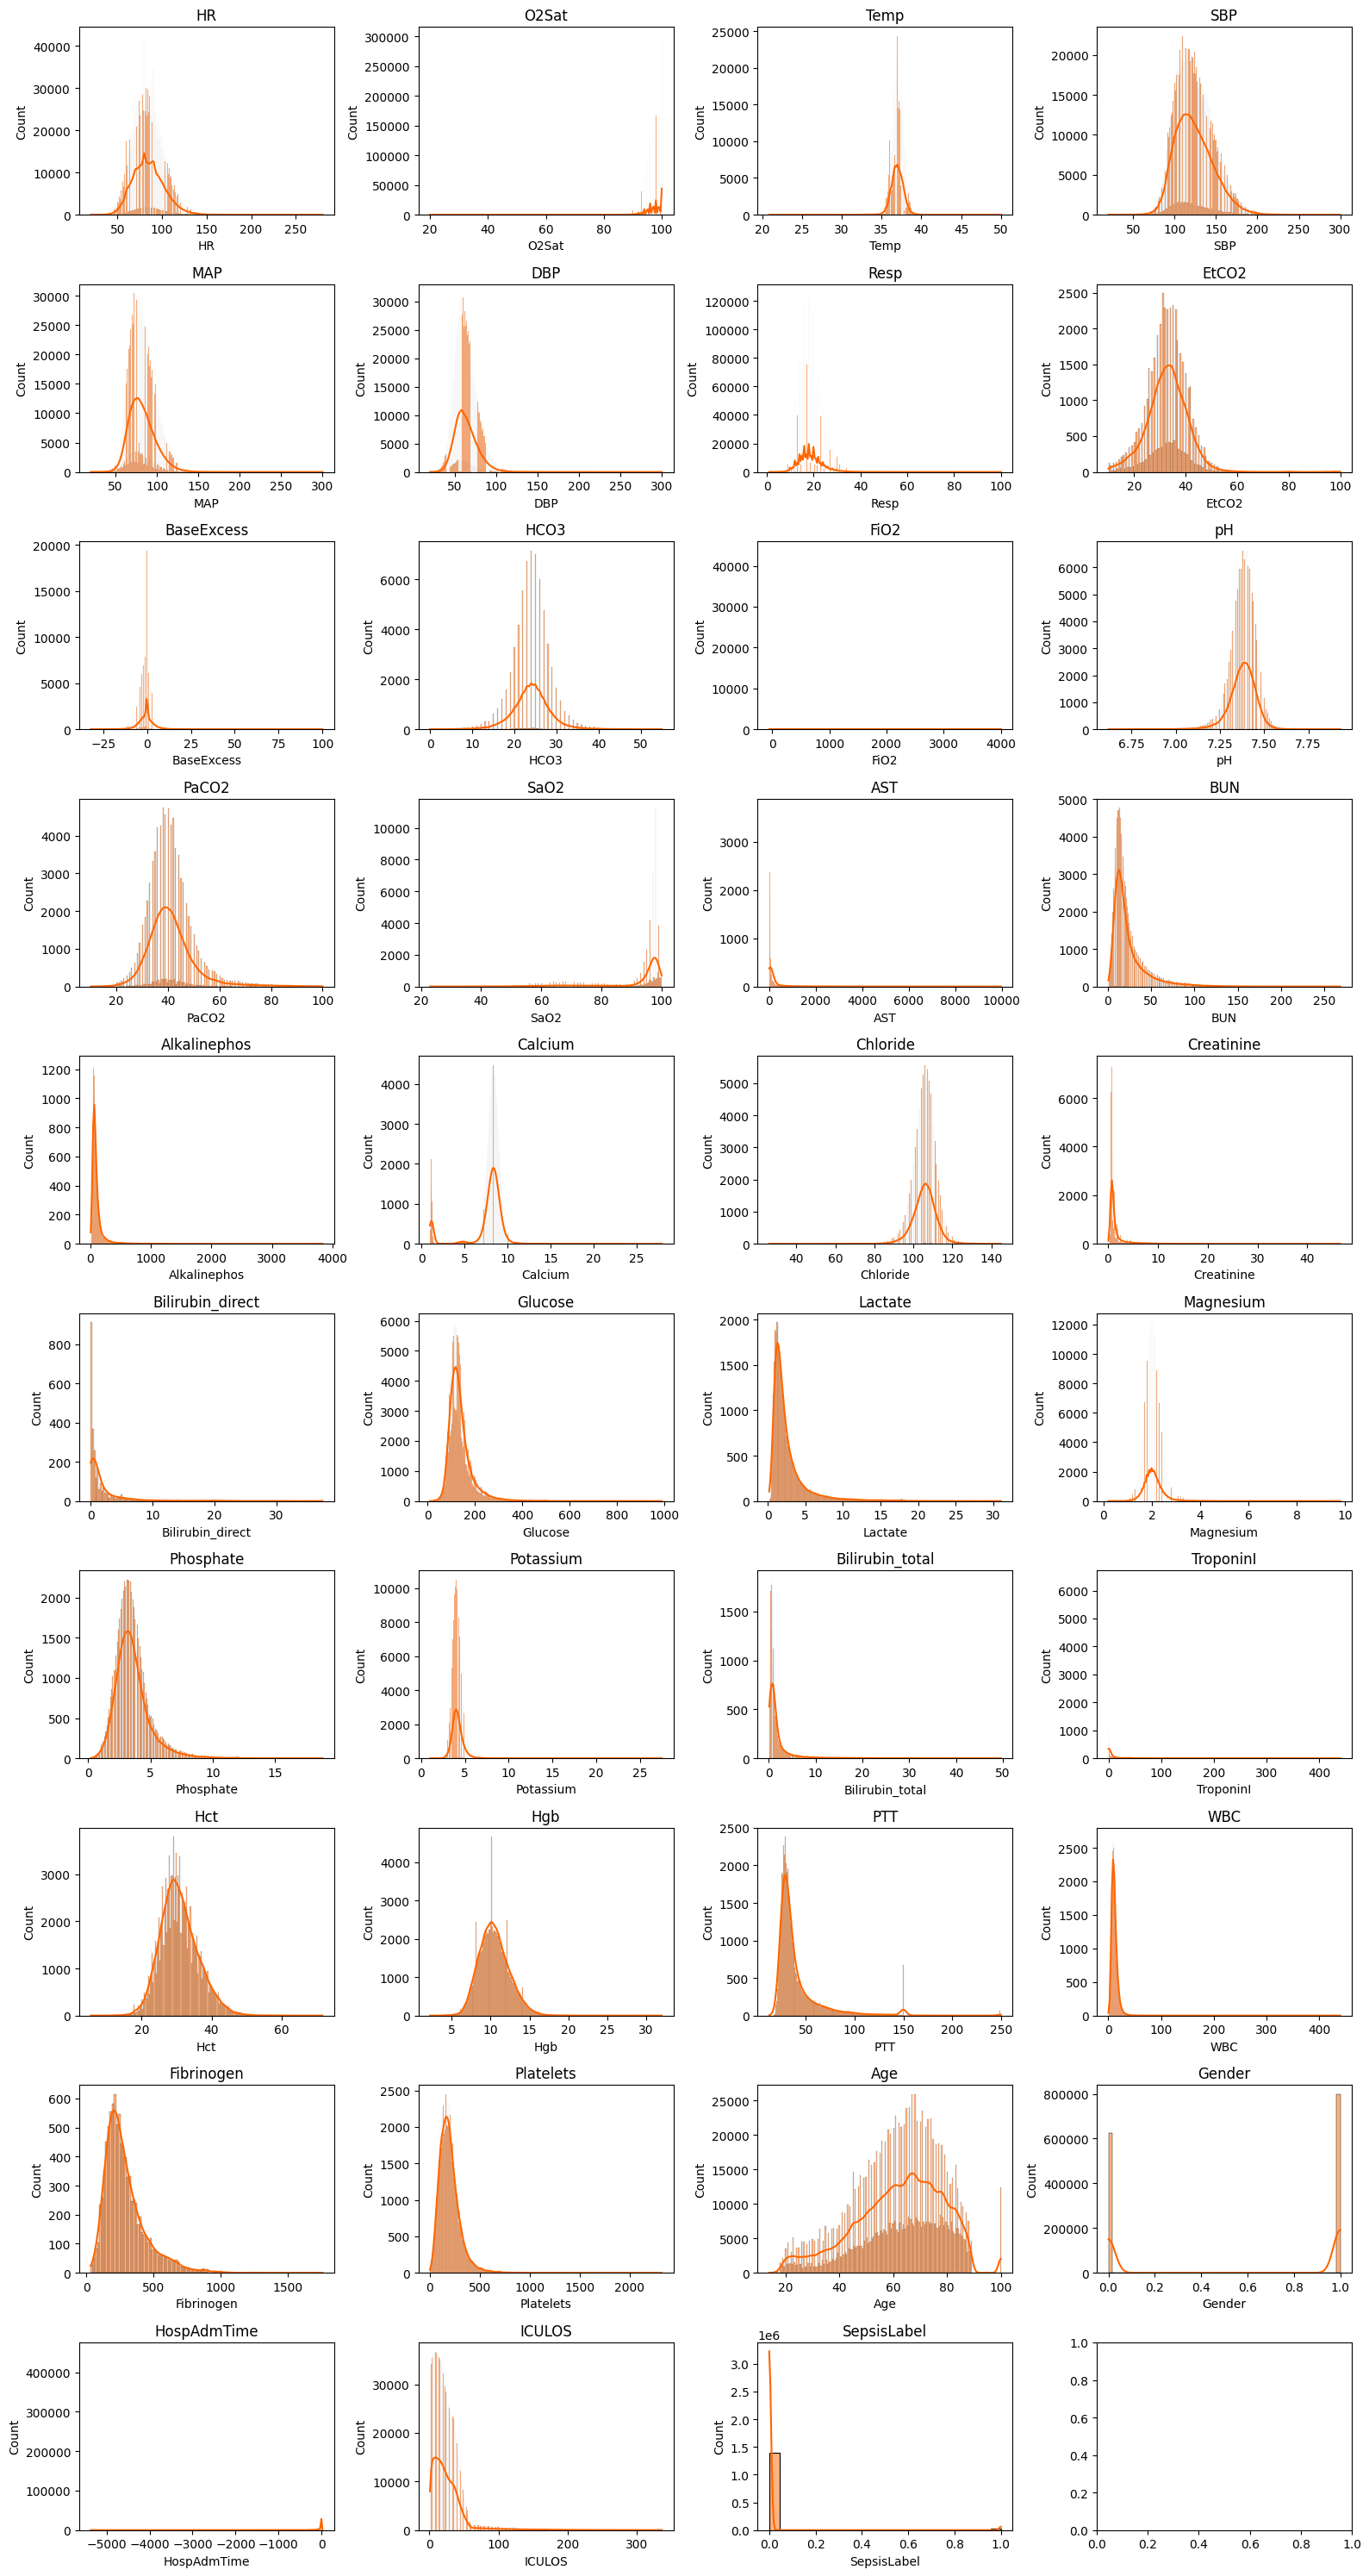

In [10]:
numerical_col = df.select_dtypes(include="number").columns.to_list()

fig, axes = plt.subplots(10, 4, figsize=(16, 30))
axes = axes.flatten()

for i, col in enumerate(numerical_col):
    sns.histplot(
        df[col],
        kde=True,
        color="#ff6600",
        ax=axes[i]
    )
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

In [11]:
skew = df.select_dtypes(include="number").skew()

skew.sort_values(key=abs, ascending=False).to_frame("skewness")

,skewness
FiO2,354.944271
WBC,15.113610
HospAdmTime,-12.388709
Alkalinephos,10.150541
SepsisLabel,7.207963
TroponinI,6.575118
AST,6.343064
Bilirubin_total,5.128029
Creatinine,4.626545
O2Sat,-4.202288


In [12]:
df["SepsisLabel"].unique()

array([0, 1])

In [13]:
cols = ["BaseExcess", "FiO2", "HospAdmTime"]

print(df[cols].describe())

for col in cols:
    print(f"\n{col}")
    print("Negative values:", (df[col] < 0).sum())
    print("Minimum:", df[col].min())

         BaseExcess           FiO2   HospAdmTime
count  83835.000000  126218.000000  1.423111e+06
mean      -0.684036       0.555663 -5.594369e+01
std        4.292105      11.260959  1.647345e+02
min      -32.000000     -50.000000 -5.366860e+03
25%       -3.000000       0.400000 -4.578000e+01
50%        0.000000       0.500000 -5.700000e+00
75%        1.000000       0.600000 -3.000000e-02
max      100.000000    4000.000000  2.399000e+01

BaseExcess
Negative values: 38858
Minimum: -32.0

FiO2
Negative values: 2
Minimum: -50.0

HospAdmTime
Negative values: 1366541
Minimum: -5366.86


In [14]:
q1 = df["BaseExcess"].quantile(0.25)
q3 = df["BaseExcess"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 3 * iqr
df[df["BaseExcess"] > upper] 

,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,PTT,WBC,Fibrinogen,Platelets,Age,Gender,HospAdmTime,ICULOS,SepsisLabel,patient_id
3,90.0,95.0,NaN,NaN,NaN,NaN,30.0,NaN,24.0,NaN,...,NaN,NaN,NaN,NaN,83.14,0,-0.03,4,0,p000001
10,104.0,92.0,37.17,138.0,86.67,NaN,19.0,NaN,23.0,NaN,...,NaN,NaN,NaN,NaN,83.14,0,-0.03,11,0,p000001
16,103.0,90.0,NaN,NaN,NaN,NaN,30.0,NaN,21.0,45.0,...,NaN,5.7,NaN,317.0,83.14,0,-0.03,17,0,p000001
23,102.0,89.0,36.67,132.0,94.00,NaN,32.0,NaN,20.0,NaN,...,NaN,NaN,NaN,NaN,83.14,0,-0.03,24,0,p000001
38,108.0,89.0,NaN,139.0,102.33,NaN,26.0,NaN,20.0,NaN,...,NaN,NaN,NaN,NaN,83.14,0,-0.03,39,0,p000001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
788851,58.0,95.0,36.78,105.0,78.33,NaN,20.0,NaN,18.0,NaN,...,NaN,NaN,NaN,NaN,78.82,0,-0.05,10,0,p020610
788863,63.0,36.0,NaN,107.0,59.67,NaN,21.0,NaN,19.0,NaN,...,NaN,NaN,NaN,NaN,78.82,0,-0.05,22,0,p020610
788864,77.0,96.0,NaN,120.0,70.00,NaN,31.0,NaN,17.0,NaN,...,NaN,NaN,NaN,NaN,78.82,0,-0.05,23,0,p020610
934036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.3,35.3,...,NaN,NaN,NaN,NaN,45.00,1,-4.19,89,0,p103815


In [15]:
print(df["BaseExcess"].quantile([0.001, 0.01, 0.99, 0.999]))  

df.loc[(df["BaseExcess"] > 40) | (df["BaseExcess"] < -40), "BaseExcess"] = np.nan

0.001   -22.0
0.010   -13.0
0.990    11.0
0.999    19.0
Name: BaseExcess, dtype: float64


In [16]:
print(df.loc[df["FiO2"] < 0, "FiO2"].value_counts())
print(df.loc[df["FiO2"] > 1, "FiO2"].quantile(
    [0.5, 0.9, 0.99, 1.0]
))

FiO2
-50.0    2
Name: count, dtype: int64
0.50       2.00
0.90       6.22
0.99    3042.40
1.00    4000.00
Name: FiO2, dtype: float64


In [17]:
df.loc[(df["FiO2"] < 0) | (df["FiO2"] > 1), "FiO2"] = np.nan
print(df.loc[df["FiO2"] < 0, "FiO2"].value_counts())


Series([], Name: count, dtype: int64)


In [18]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100,
    "unique_values": df.nunique()
}).sort_values("missing_pct", ascending=False)

print(missing_report.round(2))

                  missing_count  missing_pct  unique_values
Bilirubin_direct        1420437        99.81            267
Fibrinogen              1413615        99.33            812
TroponinI               1410626        99.12           2179
Bilirubin_total         1402238        98.53            402
Alkalinephos            1400430        98.41            732
AST                     1400181        98.39           1952
Lactate                 1384276        97.27           1271
PTT                     1378712        96.88           1391
EtCO2                   1376191        96.70            134
SaO2                    1372197        96.42            419
Phosphate               1364683        95.89            187
HCO3                    1358325        95.45            287
Chloride                1353454        95.10            105
Calcium                 1340736        94.21            527
PaCO2                   1339897        94.15            529
BaseExcess              1339287        9

In [19]:
missing_pct = df.isna().mean().mul(100).sort_values(ascending=False)

missing_pct.to_frame("missing_pct").round(2)

,missing_pct
Bilirubin_direct,99.81
Fibrinogen,99.33
TroponinI,99.12
Bilirubin_total,98.53
Alkalinephos,98.41
AST,98.39
Lactate,97.27
PTT,96.88
EtCO2,96.70
SaO2,96.42


In [20]:
time_cols = [c for c in df.columns if c not in
            ["Age", "Gender", "HospAdmTime", "ICULOS", "SepsisLabel", "patient_id"]]

df = df.sort_values(["patient_id", "ICULOS"])
flags = df[time_cols].notna().astype("int8").add_suffix("_measured")
df = pd.concat([df, flags], axis=1)
df[time_cols] = df.groupby("patient_id")[time_cols].ffill()

In [21]:
from sklearn.model_selection import GroupShuffleSplit

X = df.drop(columns=["SepsisLabel", "patient_id"])
y = df["SepsisLabel"]
groups = df["patient_id"]

# First: 70% train, 30% temporary
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    gss.split(X, y, groups=groups)
)

# Second: divide temporary into 15% validation, 15% test
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss.split(
        X.iloc[temp_idx],
        y.iloc[temp_idx],
        groups=groups.iloc[temp_idx]
    )
)
val_idx  = temp_idx[val_idx]
test_idx = temp_idx[test_idx]

# Create the datasets
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

In [22]:
tr, va, te = (set(groups.iloc[i]) for i in (train_idx, val_idx, test_idx))
print(len(tr & va), len(tr & te), len(va & te))

0 0 0


In [23]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

pipe = Pipeline([
    ("imputer" ,SimpleImputer(strategy="median")),
    ("scalar", StandardScaler())
])

X_train = pipe.fit_transform(X_train)   
X_val   = pipe.transform(X_val)         
X_test  = pipe.transform(X_test)

## Building The Network (ANN)

In [24]:
import keras 
from keras.layers import Dense


model_base = keras.Sequential([
    keras.Input(shape =( X_train.shape[1],)),
    Dense(512, activation="relu" ),
    Dense(256, activation="relu" ),
    Dense(128, activation="relu" ),
    Dense(64, activation="relu" ),
    Dense(32, activation="relu" ),
    Dense(1, activation="sigmoid" )
])

model_base.compile(optimizer="adam", loss="binary_crossentropy", metrics=["recall", "accuracy", keras.metrics.AUC(name="auc")])

In [25]:
X_train = X_train.astype("float32"); X_val = X_val.astype("float32"); X_test = X_test.astype("float32")

neg, pos = np.bincount(y_train)
class_weight = {0: 1.0, 1: neg / pos}     
print(y_train.mean(), class_weight)

early =  keras.callbacks.EarlyStopping(monitor="val_auc", patience=4, restore_best_weights=True, mode="max")

history = model_base.fit(
    X_train, y_train,
    epochs=10,
    batch_size=2048,
    validation_data=(X_val, y_val),
    class_weight=class_weight,
    callbacks=[early]
)

0.01851114848716959 {0: 1.0, 1: np.float64(53.02149956784788)}
Epoch 1/10
489/489 ━━━━━━━━━━━━━━━━━━━━ 19s 34ms/step - accuracy: 0.7251 - auc: 0.8023 - loss: 1.0635 - recall: 0.7310 - val_accuracy: 0.7920 - val_auc: 0.7909 - val_loss: 0.4363 - val_recall: 0.6345
Epoch 2/10
489/489 ━━━━━━━━━━━━━━━━━━━━ 14s 28ms/step - accuracy: 0.7586 - auc: 0.8559 - loss: 0.9272 - recall: 0.7949 - val_accuracy: 0.7457 - val_auc: 0.7995 - val_loss: 0.4860 - val_recall: 0.7087
Epoch 3/10
489/489 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.7860 - auc: 0.8886 - loss: 0.8209 - recall: 0.8312 - val_accuracy: 0.7916 - val_auc: 0.7848 - val_loss: 0.4252 - val_recall: 0.6334
Epoch 4/10
489/489 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.8205 - auc: 0.9167 - loss: 0.7150 - recall: 0.8607 - val_accuracy: 0.8248 - val_auc: 0.7640 - val_loss: 0.3940 - val_recall: 0.5739
Epoch 5/10
489/489 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - accuracy: 0.8454 - auc: 0.9363 - loss: 0.6246 - recall: 0.8783 - val_accuracy: 0.

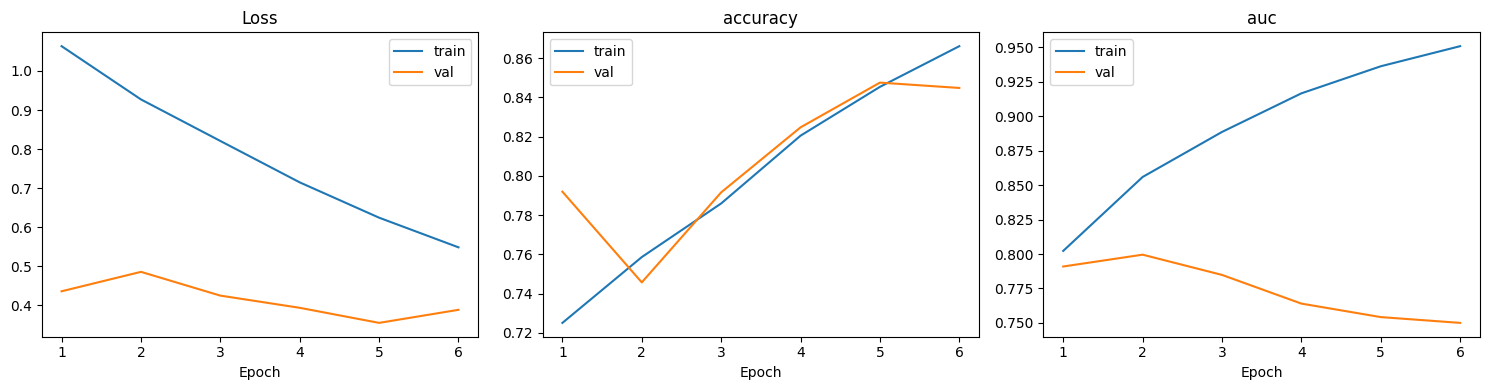

In [26]:
h = history.history
epochs = range(1, len(h["loss"] ) + 1)

fig, ax = plt.subplots(1, 3, figsize=(15,4))

ax[0].plot(epochs, h["loss"], label= "train")
ax[0].plot(epochs, h["val_loss"], label= "val")
ax[0].set_title("Loss")

ax[1].plot(epochs, h["accuracy"], label="train")
ax[1].plot(epochs, h["val_accuracy"], label="val")
ax[1].set_title("accuracy")

ax[2].plot(epochs, h["auc"], label= "train")
ax[2].plot(epochs, h["val_auc"], label="val")
ax[2].set_title("auc")


for a in ax:
    a.set_xlabel("Epoch")
    a.legend()

plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_recall_curve, classification_report,
                             confusion_matrix)

val_prob  = model_base.predict(X_val,  batch_size=4096).ravel()
test_prob = model_base.predict(X_test, batch_size=4096).ravel()

52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step


In [28]:
print("Val  AUROC:", roc_auc_score(y_val, val_prob))
print("Test AUROC:", roc_auc_score(y_test, test_prob))
print("Val  AUPRC:", average_precision_score(y_val, val_prob))
print("Test AUPRC:", average_precision_score(y_test, test_prob))
print("Baseline AUPRC (positive rate):", y_test.mean())

Val  AUROC: 0.7995117230967632
Test AUROC: 0.7907286056725273
Val  AUPRC: 0.09386072898615225
Test AUPRC: 0.08346278782389978
Baseline AUPRC (positive rate): 0.016877438323375866


In [29]:
p, r, t = precision_recall_curve(y_val, val_prob)
f1 = 2 * p * r / (p + r + 1e-9)
best_t = t[f1[:-1].argmax()]
print("Best threshold:", best_t)

test_pred = (test_prob >= best_t).astype(int)
print(confusion_matrix(y_test, test_pred))
print(classification_report(y_test, test_pred, digits=3))

Best threshold: 0.81984687
[[201173   7481]
 [  2630    952]]
              precision    recall  f1-score   support

           0      0.987     0.964     0.975    208654
           1      0.113     0.266     0.158      3582

    accuracy                          0.952    212236
   macro avg      0.550     0.615     0.567    212236
weighted avg      0.972     0.952     0.962    212236



## Official Validation from Physionet GitHub

In [30]:
from evaluate_sepsis_score import compute_prediction_utility
import numpy as np, pandas as pd

def utility_score(y_true, y_prob, pids, threshold):
    y_true = np.asarray(y_true); pred_all = (np.asarray(y_prob) >= threshold).astype(int)
    idx = pd.DataFrame({"pid": np.asarray(pids)}).groupby("pid", sort=False).indices

    obs = best = inaction = 0.0
    for ix in idx.values():                       # rows are already in time order per patient
        labels, preds = y_true[ix], pred_all[ix]
        n = len(labels)

        best_preds = np.zeros(n)
        if labels.any():
            t_sepsis = np.argmax(labels) + 6      # onset = first label=1 plus 6 hours
            best_preds[max(0, t_sepsis - 12): min(t_sepsis + 4, n)] = 1

        obs      += compute_prediction_utility(labels, preds,      check_errors=False)
        best     += compute_prediction_utility(labels, best_preds, check_errors=False)
        inaction += compute_prediction_utility(labels, np.zeros(n), check_errors=False)

    return (obs - inaction) / (best - inaction)   # 1 = perfect, 0 = never predicts sepsis

In [31]:
val_pids  = groups.iloc[val_idx]
test_pids = groups.iloc[test_idx]

best_t, best_u = 0.5, -1
for t in np.arange(0.05, 1.0, 0.05):
    u = utility_score(y_val, val_prob, val_pids, t)
    if u > best_u: best_t, best_u = t, u

print("Best val threshold:", best_t, "| Val utility:", best_u)
print("Test utility:", utility_score(y_test, test_prob, test_pids, best_t))

Best val threshold: 0.6000000000000001 | Val utility: 0.33172377538006115
Test utility: 0.3109931412894446


## Improved Model !!

In [46]:
from keras.layers import Dropout

model_improved = keras.Sequential([
    keras.Input(shape =( X_train.shape[1],)),
    Dense(256, activation="relu" ),
    Dropout(0.4),

    Dense(128, activation="relu" ),
    Dropout(0.4),

    Dense(64, activation="relu" ),
    Dropout(0.4),
    
    Dense(1, activation="sigmoid" )
])

model_improved.compile(optimizer="adam", loss="binary_crossentropy", metrics=["recall", "accuracy", keras.metrics.AUC(name="auc")])

In [49]:
neg, pos = np.bincount(y_train)
class_weight = {0: 1.0, 1: neg / pos}     
print(y_train.mean(), class_weight)

0.01851114848716959 {0: 1.0, 1: np.float64(53.02149956784788)}


In [50]:
optimizer = keras.optimizers.Adam(learning_rate=1e-3)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_auc",
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=3,
    restore_best_weights=True
)

history = model_improved.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=2048,
    class_weight=class_weight,
    callbacks=[reduce_lr, early_stop]
)

Epoch 1/30
489/489 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.6969 - auc: 0.7440 - loss: 1.1811 - recall: 0.6654 - val_accuracy: 0.7545 - val_auc: 0.7811 - val_loss: 0.5202 - val_recall: 0.6633 - learning_rate: 0.0010
Epoch 2/30
489/489 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.7243 - auc: 0.7842 - loss: 1.1096 - recall: 0.7097 - val_accuracy: 0.7752 - val_auc: 0.7928 - val_loss: 0.4665 - val_recall: 0.6589 - learning_rate: 0.0010
Epoch 3/30
489/489 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.7277 - auc: 0.7996 - loss: 1.0765 - recall: 0.7291 - val_accuracy: 0.7706 - val_auc: 0.8009 - val_loss: 0.4641 - val_recall: 0.6746 - learning_rate: 0.0010
Epoch 4/30
489/489 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.7250 - auc: 0.8111 - loss: 1.0474 - recall: 0.7476 - val_accuracy: 0.7649 - val_auc: 0.8033 - val_loss: 0.4776 - val_recall: 0.6851 - learning_rate: 0.0010
Epoch 5/30
489/489 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.7274 - auc: 0.8204 - loss: 1.0253 - reca

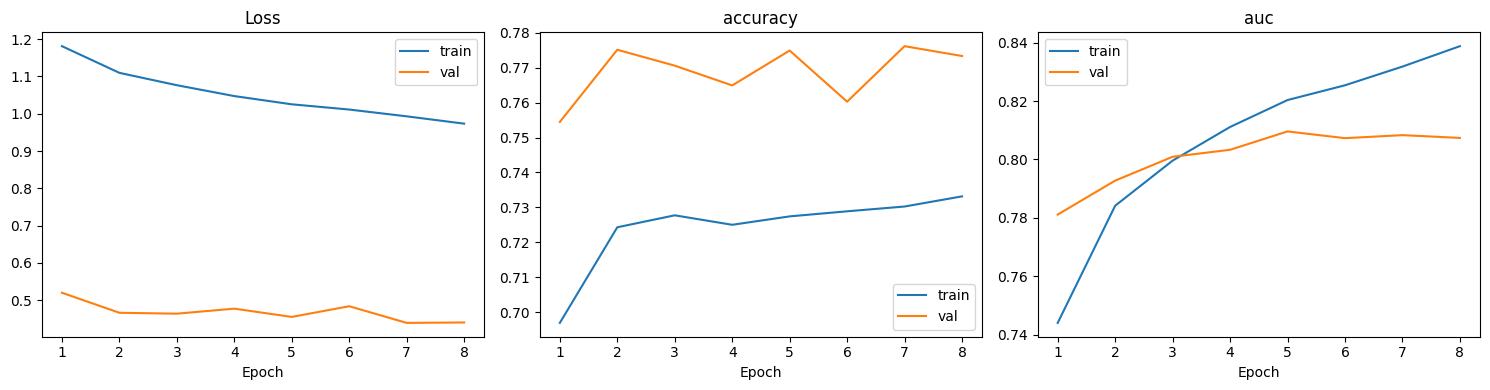

In [51]:
h = history.history
epochs = range(1, len(h["loss"] ) + 1)

fig, ax = plt.subplots(1, 3, figsize=(15,4))

ax[0].plot(epochs, h["loss"], label= "train")
ax[0].plot(epochs, h["val_loss"], label= "val")
ax[0].set_title("Loss")

ax[1].plot(epochs, h["accuracy"], label="train")
ax[1].plot(epochs, h["val_accuracy"], label="val")
ax[1].set_title("accuracy")

ax[2].plot(epochs, h["auc"], label= "train")
ax[2].plot(epochs, h["val_auc"], label="val")
ax[2].set_title("auc")


for a in ax:
    a.set_xlabel("Epoch")
    a.legend()

plt.tight_layout()
plt.show()

In [52]:
val_prob  = model_improved.predict(X_val,  batch_size=4096).ravel()
test_prob = model_improved.predict(X_test, batch_size=4096).ravel()
print("Val  AUROC:", roc_auc_score(y_val, val_prob))
print("Test AUROC:", roc_auc_score(y_test, test_prob))
print("Val  AUPRC:", average_precision_score(y_val, val_prob))
print("Test AUPRC:", average_precision_score(y_test, test_prob))
print("Baseline AUPRC (positive rate):", y_test.mean())

52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Val  AUROC: 0.8096059986284552
Test AUROC: 0.808001394939676
Val  AUPRC: 0.09269973978620624
Test AUPRC: 0.09887361578275125
Baseline AUPRC (positive rate): 0.016877438323375866


In [53]:
p, r, t = precision_recall_curve(y_val, val_prob)
f1 = 2 * p * r / (p + r + 1e-9)
best_t = t[f1[:-1].argmax()]
print("Best threshold:", best_t)

test_pred = (test_prob >= best_t).astype(int)
print(confusion_matrix(y_test, test_pred))
print(classification_report(y_test, test_pred, digits=3))

Best threshold: 0.69324905
[[199348   9306]
 [  2380   1202]]
              precision    recall  f1-score   support

           0      0.988     0.955     0.972    208654
           1      0.114     0.336     0.171      3582

    accuracy                          0.945    212236
   macro avg      0.551     0.645     0.571    212236
weighted avg      0.973     0.945     0.958    212236



In [54]:
val_pids  = groups.iloc[val_idx]
test_pids = groups.iloc[test_idx]

best_t, best_u = 0.5, -1
for t in np.arange(0.05, 1.0, 0.05):
    u = utility_score(y_val, val_prob, val_pids, t)
    if u > best_u: best_t, best_u = t, u

print("Best val threshold:", best_t, "| Val utility:", best_u)
print("Test utility:", utility_score(y_test, test_prob, test_pids, best_t))

Best val threshold: 0.55 | Val utility: 0.36175669619773404
Test utility: 0.3542588020118908
